# MSDS 565 — Project 3: Movie Genre Classification
## Notebook 3 — Interpreting the TF-IDF models


Notebook 2 told me how the models performed. Here I'm looking at **why** they made those predictions. I'm using the three original IMDB-trained TF-IDF logistic regression models, because their coefficients connect directly to vocabulary and are compatible with SHAP's linear explainer. I use the same 100-vote filter, same selected genres, and same held-out test split as Notebook 2. No new models are trained here.

### 1. Load the exact test population and fitted artifacts

I rebuild the test data from the provided CSV, apply the same filter, and load the TF-IDF pipeline and trained classifiers from `models/`. The only predictor is `plot_synopsis`. Movie titles and ratings are there for filtering and interpreting examples, not as input features.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import sparse
from sklearn.metrics import confusion_matrix
from IPython.display import display

GENRES = ["Action", "Comedy", "Horror"]
MIN_VOTES = 100
ROOT = Path.cwd()
for candidate in [ROOT, ROOT.parent, ROOT.parent.parent]:
    if (candidate / "mpst_imdb_movies.csv").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Place the course CSV in the project root or notebook folder.")
MODEL_DIR = ROOT / "models"
df = pd.read_csv(ROOT / "mpst_imdb_movies.csv", low_memory=False)
df["numVotes"] = pd.to_numeric(df["numVotes"], errors="coerce")
df = df[df["numVotes"] >= MIN_VOTES].copy()
df["split"] = df["split"].astype(str).str.lower().str.strip()
df["plot_synopsis"] = df["plot_synopsis"].fillna("").astype(str)
df = df[df["plot_synopsis"].str.strip().ne("")].copy()
for genre in GENRES:
    df[genre] = pd.to_numeric(df[genre], errors="raise").astype(int)
test_df = df[df["split"].eq("test")].copy().reset_index(drop=True)
vectorizer = joblib.load(MODEL_DIR / "P3_N2_tfidf_vectorizer.pkl")
scaler = joblib.load(MODEL_DIR / "P3_N2_tfidf_scaler.pkl")
models = {genre: joblib.load(MODEL_DIR / f"P3_N2_tfidf_logreg_{genre.lower()}.pkl")
          for genre in GENRES}
X_test = scaler.transform(vectorizer.transform(test_df["plot_synopsis"]))
feature_names = np.asarray(vectorizer.get_feature_names_out())
assert X_test.shape[1] == len(feature_names)
print(f"Held-out test movies: {len(test_df):,} | TF-IDF features: {X_test.shape[1]:,}")

Held-out test movies: 2,330 | TF-IDF features: 20,000


### 2. Which words push each prediction up or down?

I plot the ten largest positive and ten largest negative coefficients for each genre. Positive coefficients move a prediction toward that genre; negative ones move it away. I standardized the TF-IDF features in Notebook 2, which helps make the coefficient sizes more comparable. But coefficient size alone isn't the same as a word's contribution to actual predictions.

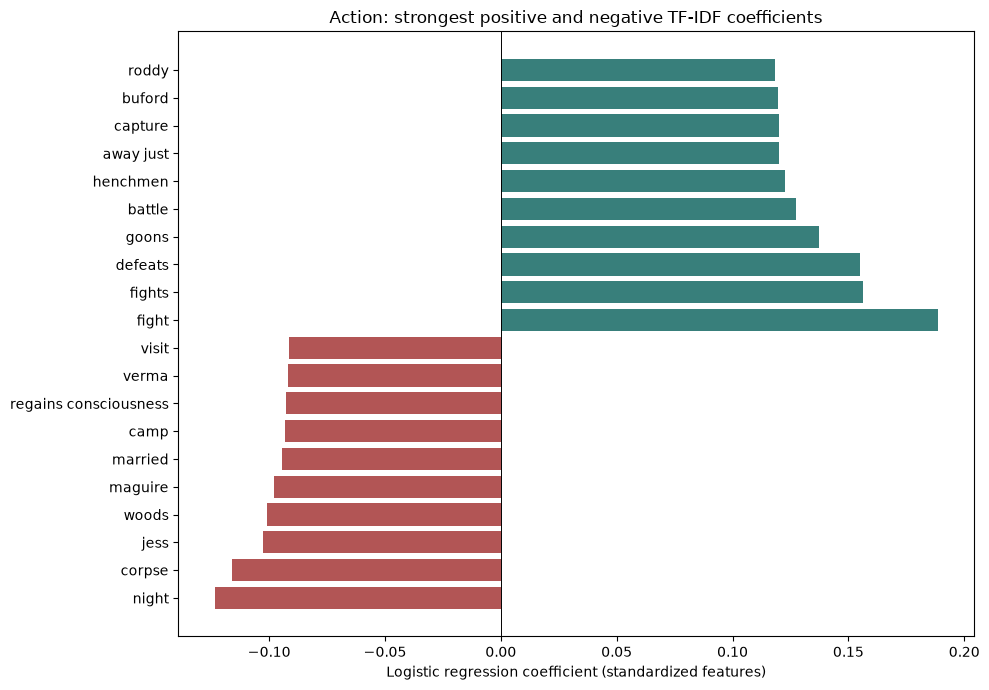

Action | positive: fight, fights, defeats, goons, battle | negative: night, corpse, jess, woods, maguire


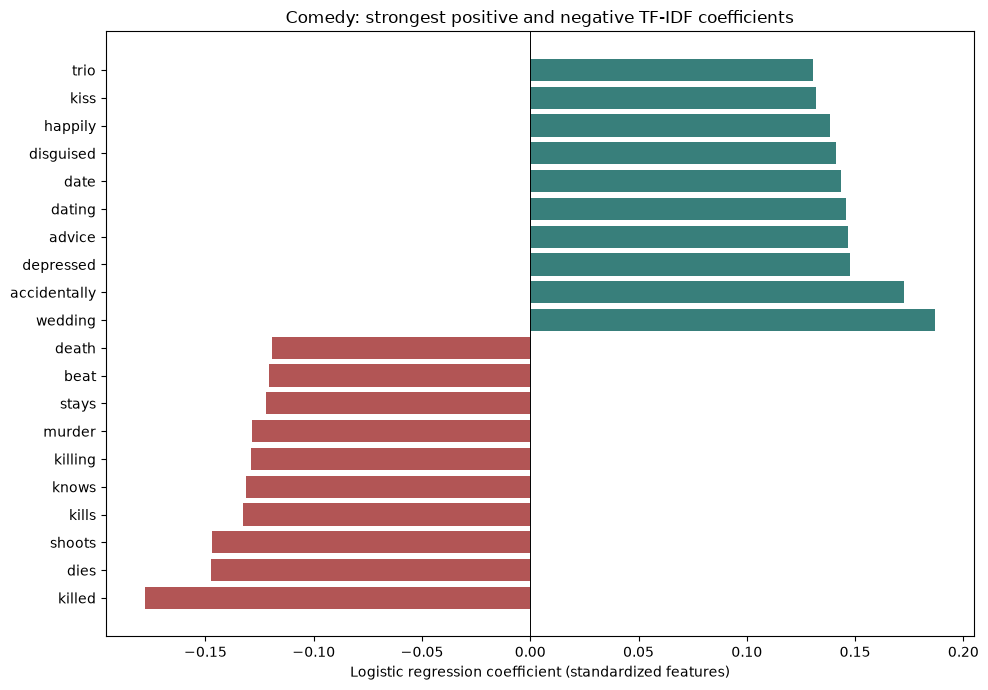

Comedy | positive: wedding, accidentally, depressed, advice, dating | negative: killed, dies, shoots, kills, knows


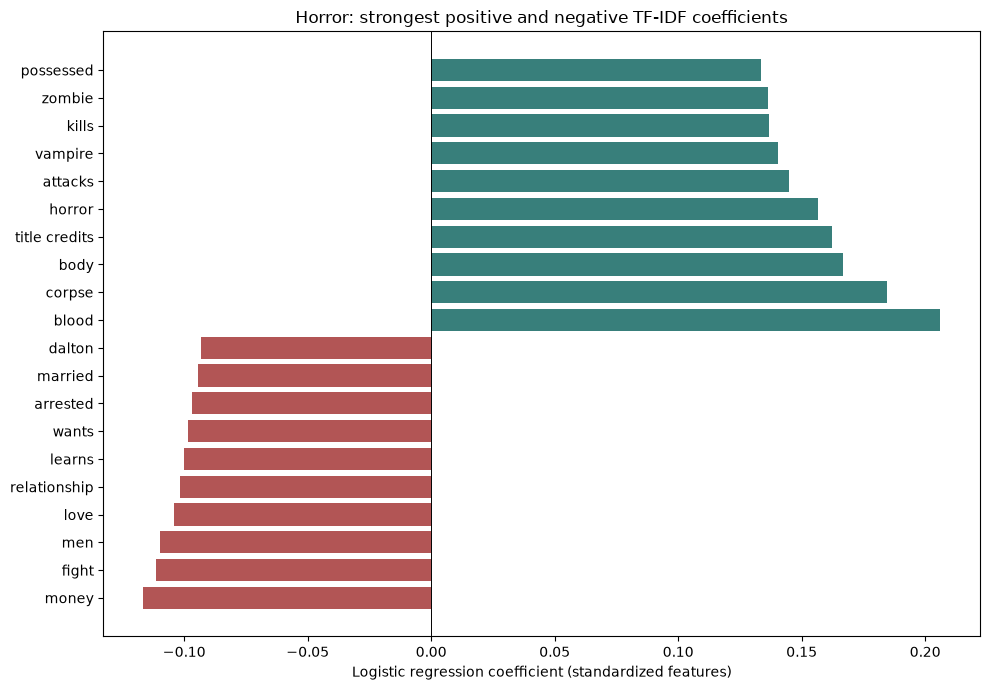

Horror | positive: blood, corpse, body, title credits, horror | negative: money, fight, men, love, relationship


In [2]:
for genre, model in models.items():
    coef = model.coef_[0]
    pos = np.argsort(coef)[-10:][::-1]
    neg = np.argsort(coef)[:10]
    ordered = np.concatenate([neg, pos])
    colors = ["#b25555"] * len(neg) + ["#387f7b"] * len(pos)
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(feature_names[ordered], coef[ordered], color=colors)
    ax.axvline(0, color="black", linewidth=0.7)
    ax.set_title(f"{genre}: strongest positive and negative TF-IDF coefficients")
    ax.set_xlabel("Logistic regression coefficient (standardized features)")
    plt.tight_layout()
    plt.show()
    print(f"{genre} | positive: {', '.join(feature_names[pos[:5]])} | negative: {', '.join(feature_names[neg[:5]])}")

### 3. SHAP on held-out test movies

I'm using SHAP's `LinearExplainer` for **Horror** as my deep dive. I use training-derived preprocessing from Notebook 2 and explain the test predictions, rather than fitting a new text model. To keep a large sparse text matrix manageable on my laptop, I explain a reproducible sample of up to 200 test movies; that is still a subset of the held-out test set. I use a zero vector as the explicit baseline in standardized TF-IDF space, and interpret values as shifts in **log-odds**, not probabilities.

The bar plot tells me which words matter most **on average**. Unlike the coefficient chart, SHAP considers how often those words actually contribute across the sampled predictions.

In [8]:
%pip install "shap==0.46.0" --no-deps
%pip install "slicer==0.0.8" --no-deps
%pip install "numba==0.60.0" "llvmlite==0.43.0" --no-deps

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 20.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.1/31.1 MB 59.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [llvmlite]1/2 [llvmlite]
Note: you may need to restart the kernel to use updated packages.


/Applications/anaconda3/envs/moviegenre/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


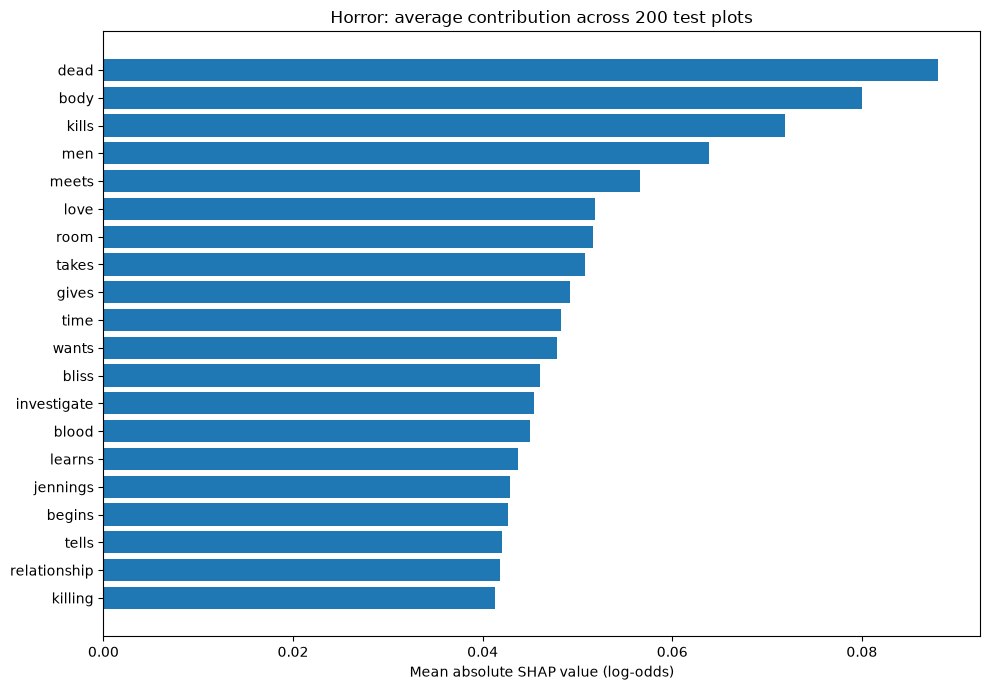

Top SHAP terms: dead, body, kills, men, meets, love, room, takes, gives, time


In [9]:
import shap

SHAP_GENRE = "Horror"
SHAP_SAMPLE_SIZE = min(200, len(test_df))
sample_idx = np.random.default_rng(42).choice(len(test_df), size=SHAP_SAMPLE_SIZE, replace=False)
X_explain = X_test[sample_idx]
model = models[SHAP_GENRE]
# This sparse-safe, zero-valued background is explicit and reproducible.
background = sparse.csr_matrix((1, X_test.shape[1]), dtype=X_test.dtype)
explainer = shap.LinearExplainer(model, background)
shap_values = explainer(X_explain)
mean_abs = np.abs(shap_values.values).mean(axis=0)
top_idx = np.argsort(mean_abs)[-20:][::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(feature_names[top_idx][::-1], mean_abs[top_idx][::-1])
ax.set_xlabel("Mean absolute SHAP value (log-odds)")
ax.set_title(f"{SHAP_GENRE}: average contribution across {SHAP_SAMPLE_SIZE} test plots")
plt.tight_layout()
plt.show()
print("Top SHAP terms:", ', '.join(feature_names[top_idx[:10]]))

### 4. What does the beeswarm add?

The mean-absolute-value chart collapses direction and variation into a single ranking. The beeswarm lets me see whether a term pushes individual predictions up or down, how widely its contribution varies, and whether the feature is present at a higher or lower value. I restrict the display to the same top terms so the plot stays readable.

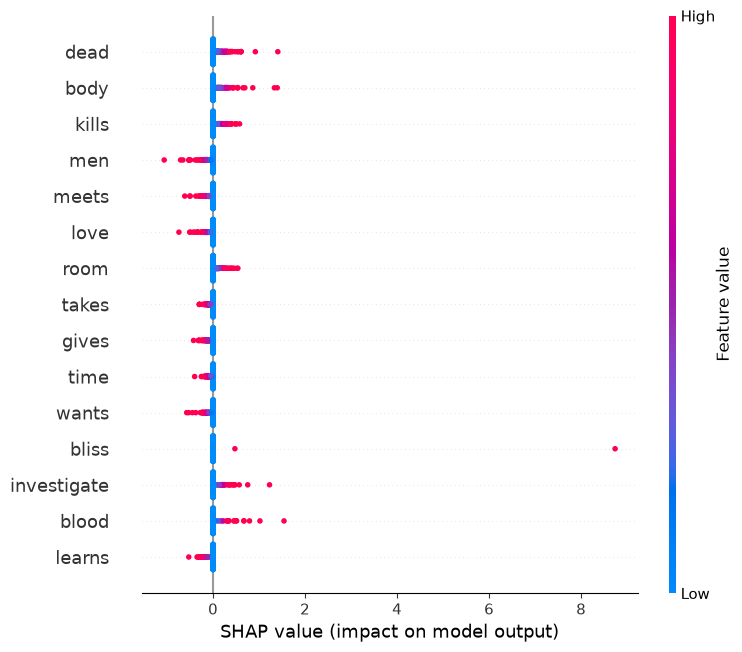

In [10]:
# Restrict to the top features to avoid allocating a dense copy of the full vocabulary.
bee_idx = top_idx[:15]
bee_values = shap.Explanation(
    values=shap_values.values[:, bee_idx],
    base_values=np.asarray(shap_values.base_values),
    data=X_explain[:, bee_idx].toarray(),
    feature_names=feature_names[bee_idx].tolist()
)
shap.plots.beeswarm(bee_values, max_display=15, show=True)

### 5. Inspect individual predictions: one confidently right, one confidently wrong

For a correct prediction, I choose the movie with the largest classification margin among correctly classified examples. For an error, I pick the mistake with the strongest confidence in the wrong direction. These are based on the same Horror model and held-out movies—not handpicked movie titles. The waterfall plots show which words made those particular predictions move away from the baseline.

Confidently correct: Colors | true=0 | predicted=0 | P(Horror)=0.000


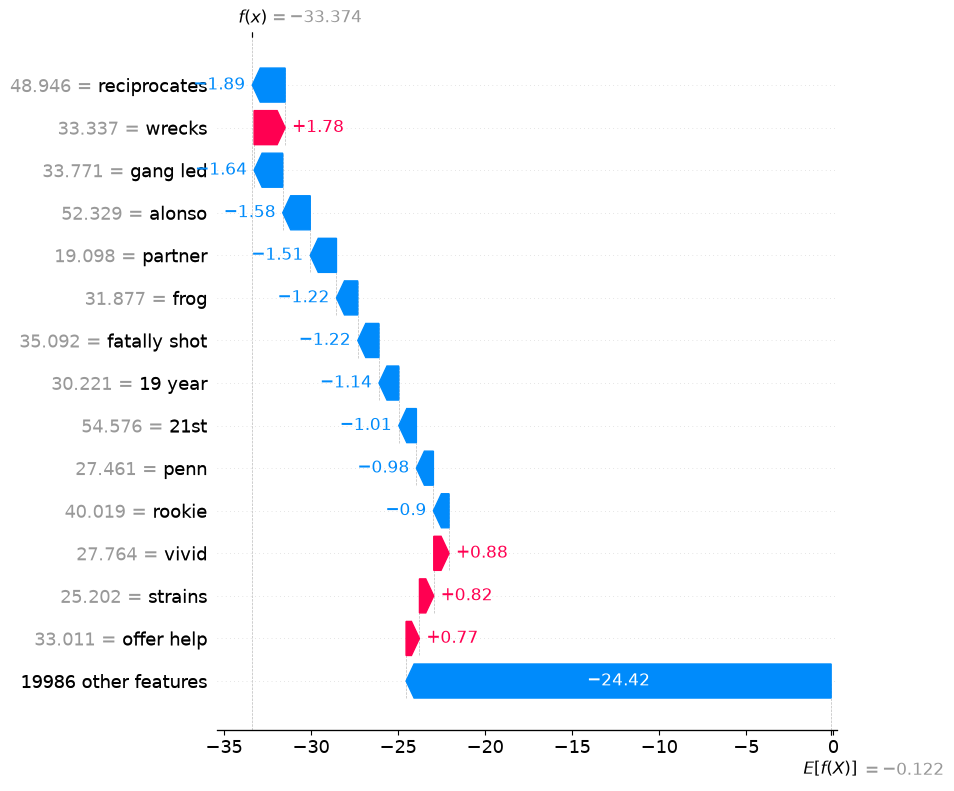

Confidently wrong: Night of the Demons | true=0 | predicted=1 | P(Horror)=1.000


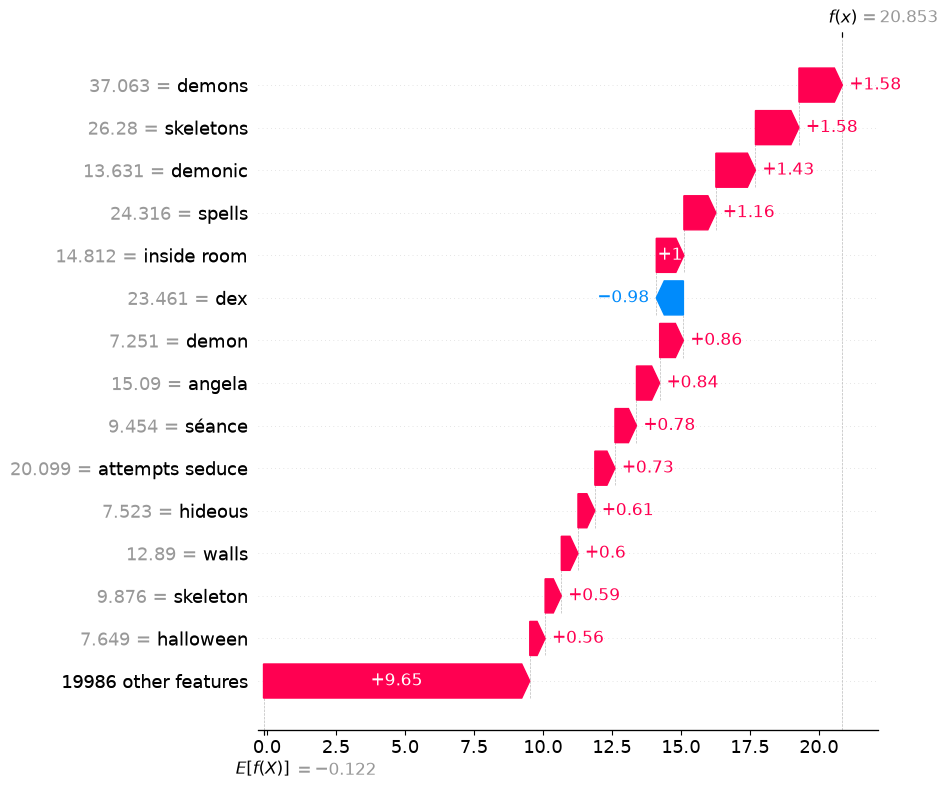

In [11]:
y_true = test_df[SHAP_GENRE].to_numpy()
prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)
confidence = np.maximum(prob, 1 - prob)
correct_idx = np.flatnonzero(pred == y_true)
wrong_idx = np.flatnonzero(pred != y_true)
assert len(correct_idx), "No correctly classified movies found."
assert len(wrong_idx), "No misclassified movies found."
chosen = [("Confidently correct", correct_idx[np.argmax(confidence[correct_idx])]),
          ("Confidently wrong", wrong_idx[np.argmax(confidence[wrong_idx])])]
for label, ix in chosen:
    row = test_df.iloc[ix]
    print(f"{label}: {row['primaryTitle']} | true={y_true[ix]} | predicted={pred[ix]} | P(Horror)={prob[ix]:.3f}")
    point = explainer(X_test[ix])
    # Limit the displayed waterfall labels while retaining the full explanation.
    single = shap.Explanation(
        values=np.asarray(point.values[0]),
        base_values=float(np.asarray(point.base_values).reshape(-1)[0]),
        data=X_test[ix].toarray().ravel(),
        feature_names=feature_names.tolist()
    )
    shap.plots.waterfall(single, max_display=15, show=True)

### 6. What I learned

The coefficient charts show the vocabulary the logistic regression models learned to associate with each genre. The SHAP bar plot adds a practical check: a huge coefficient doesn't automatically make a word important if it rarely shows up. The beeswarm shows why an average can hide a lot of variation between movies. Finally, the two waterfall plots make the model's reasoning tangible—one example where the evidence lined up with the IMDB label and another where it didn't.

I would not treat any of these explanations as proof that a term *causes* a genre prediction in the real world. They're explanations of this fitted linear model, using this dataset and text representation. I also need to examine the actual plots and top terms above before drawing conclusions about specific words or movies.